# Initial exploration of hospital patient satisfaction

**Research question:** To what extent can hospital characteristics, quality-of-care measures, clinical outcomes, and Medicare spending predict overall patient satisfaction at U.S. hospitals?

This analysis examines the four supplied CMS hospital-level datasets, identifies the overall hospital rating linear score, and assesses data coverage and missing values. It stops before merging a modeling dataset, imputing missing values, or fitting prediction models. Results describe the supplied files, not all U.S. hospitals.

In [1]:
from pathlib import Path
import hashlib
import platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 60)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
DATA_FILES = {
    "hcahps": Path("data/HCAHPS-Hospital.csv"),
    "general": Path("data/Hospital_General_Information.csv"),
    "outcomes": Path("data/Complications_and_Deaths-Hospital.csv"),
    "spending": Path("data/Medicare_Hospital_Spending_Per_Patient-Hospital.csv"),
}
print(f"Python {platform.python_version()} | pandas {pd.__version__} | NumPy {np.__version__} | scikit-learn {sklearn.__version__}")


Python 3.9.6 | pandas 2.3.3 | NumPy 2.0.2 | scikit-learn 1.6.1


## 1. Load and inspect the files

All columns are initially read as text. This preserves leading zeros in hospital identifiers and keeps CMS labels such as “Not Available” distinct from empty fields. Source files are not modified. File hashes identify exactly which downloads produced these results; the download dates and release dates were not provided.

In [2]:
datasets = {
    name: pd.read_csv(path, dtype="string", keep_default_na=False, encoding="utf-8-sig")
    for name, path in DATA_FILES.items()
}
file_summary = pd.DataFrame([
    {"dataset": name, "file": path.name, "rows": len(datasets[name]),
     "columns": datasets[name].shape[1],
     "unique_hospitals": datasets[name]["Facility ID"].nunique(),
     "blank_hospital_ids": int(datasets[name]["Facility ID"].str.strip().eq("").sum()),
     "exact_duplicate_rows": int(datasets[name].duplicated().sum()),
     "sha256": hashlib.sha256(path.read_bytes()).hexdigest()}
    for name, path in DATA_FILES.items()
])
display(file_summary.drop(columns="sha256"))
display(file_summary[["file", "sha256"]])
for name, df in datasets.items():
    print(f"\n{name}: actual column names and loaded types")
    display(pd.DataFrame({"column": df.columns, "dtype": df.dtypes.astype(str).to_numpy()}))
    display(df.head(2))


,dataset,file,rows,columns,unique_hospitals,blank_hospital_ids,exact_duplicate_rows
0,hcahps,HCAHPS-Hospital.csv,325720,22,4790,0,0
1,general,Hospital_General_Information.csv,5419,38,5419,0,0
2,outcomes,Complications_and_Deaths-Hospital.csv,95800,18,4790,0,0
3,spending,Medicare_Hospital_Spending_Per_Patient-Hospita...,4626,14,4626,0,0


,file,sha256
0,HCAHPS-Hospital.csv,b70e598f29552df302e30ed649d178abd1b3d3c868ae97...
1,Hospital_General_Information.csv,f874f09fef895a1ccf5bb7392dcbb2be05c9860339261b...
2,Complications_and_Deaths-Hospital.csv,2f7112969e2de2a015af8574848973dc48595ca6f2fe03...
3,Medicare_Hospital_Spending_Per_Patient-Hospita...,fcb050fecedd6af494750a7e6c46d992f2b03738f1f145...



hcahps: actual column names and loaded types


,column,dtype
0,Facility ID,string
1,Facility Name,string
2,Address,string
3,City/Town,string
4,State,string
5,ZIP Code,string
6,County/Parish,string
7,Telephone Number,string
8,HCAHPS Measure ID,string
9,HCAHPS Question,string


,Facility ID,Facility Name,Address,City/Town,State,ZIP Code,County/Parish,Telephone Number,HCAHPS Measure ID,HCAHPS Question,HCAHPS Answer Description,Patient Survey Star Rating,Patient Survey Star Rating Footnote,HCAHPS Answer Percent,HCAHPS Answer Percent Footnote,HCAHPS Linear Mean Value,Number of Completed Surveys,Number of Completed Surveys Footnote,Survey Response Rate Percent,Survey Response Rate Percent Footnote,Start Date,End Date
0,010001,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301,HOUSTON,(334) 793-8701,H_COMP_1_A_P,"Patients who reported that their nurses ""Alway...","Nurses ""always"" communicated well",Not Applicable,,76,,Not Applicable,1392,,17,,10/01/2024,09/30/2025
1,010001,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301,HOUSTON,(334) 793-8701,H_COMP_1_SN_P,"Patients who reported that their nurses ""Somet...","Nurses ""sometimes"" or ""never"" communicated well",Not Applicable,,6,,Not Applicable,1392,,17,,10/01/2024,09/30/2025


...

,column,dtype
0,Facility ID,string
1,Facility Name,string
2,Address,string
3,City/Town,string
4,State,string
5,ZIP Code,string
6,County/Parish,string
7,Telephone Number,string
8,Measure ID,string
9,Measure Name,string


,Facility ID,Facility Name,Address,City/Town,State,ZIP Code,County/Parish,Telephone Number,Measure ID,Measure Name,Compared to National,Denominator,Score,Lower Estimate,Higher Estimate,Footnote,Start Date,End Date
0,010001,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301,HOUSTON,(334) 793-8701,COMP_HIP_KNEE,Rate of complications for hip/knee replacement...,Not Available,33,3.8,Not Available,Not Available,,04/01/2023,03/31/2025
1,010001,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301,HOUSTON,(334) 793-8701,Hybrid_HWM,Hybrid Hospital-Wide All-Cause Risk Standardiz...,Not Available,4972,4.4,Not Available,Not Available,,07/01/2024,06/30/2025



spending: actual column names and loaded types


,column,dtype
0,Facility ID,string
1,Facility Name,string
2,Address,string
3,City/Town,string
4,State,string
5,ZIP Code,string
6,County/Parish,string
7,Telephone Number,string
8,Measure ID,string
9,Measure Name,string


,Facility ID,Facility Name,Address,City/Town,State,ZIP Code,County/Parish,Telephone Number,Measure ID,Measure Name,Score,Footnote,Start Date,End Date
0,010001,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301,HOUSTON,(334) 793-8701,MSPB-1,Medicare hospital spending per patient (Medica...,0.99,,01/01/2024,12/31/2024
1,010005,MARSHALL MEDICAL CENTERS,2505 U S HIGHWAY 431 NORTH,BOAZ,AL,35957,MARSHALL,(256) 593-8310,MSPB-1,Medicare hospital spending per patient (Medica...,1.00,,01/01/2024,12/31/2024


The files have different units of observation. General Information describes hospitals, while HCAHPS and Complications and Deaths contain multiple measures for each hospital. A repeated hospital identifier in these long-format datasets is expected; repeating the same hospital–measure pair would require investigation.

In [3]:
key_definitions = {"hcahps": ["Facility ID", "HCAHPS Measure ID"],
                   "general": ["Facility ID"],
                   "outcomes": ["Facility ID", "Measure ID"],
                   "spending": ["Facility ID", "Measure ID"]}
key_audit = pd.DataFrame([
    {"dataset": name, "key": " + ".join(keys),
     "rows_with_repeated_key": int(datasets[name].duplicated(keys, keep=False).sum())}
    for name, keys in key_definitions.items()
])
display(key_audit)


,dataset,key,rows_with_repeated_key
0,hcahps,Facility ID + HCAHPS Measure ID,0
1,general,Facility ID,0
2,outcomes,Facility ID + Measure ID,0
3,spending,Facility ID + Measure ID,0


## 2. Identify the satisfaction target

The target is the observed measure **`H_HSP_RATING_LINEAR_SCORE`**, labeled **“Overall hospital rating - linear mean score”**, using **`HCAHPS Linear Mean Value`**. This is separate from the star rating and the percentages of patients choosing individual rating categories. The intended scale is 0–100; the code checks the observed values against that range. No individual patient responses are available in these aggregate files.

In [4]:
hcahps = datasets["hcahps"]
rating_measures = hcahps.loc[
    hcahps["HCAHPS Measure ID"].str.startswith("H_HSP_RATING"),
    ["HCAHPS Measure ID", "HCAHPS Question", "HCAHPS Answer Description"]
].drop_duplicates()
display(rating_measures)
TARGET_MEASURE = "H_HSP_RATING_LINEAR_SCORE"
TARGET_COLUMN = "HCAHPS Linear Mean Value"
target_rows = hcahps.loc[hcahps["HCAHPS Measure ID"].eq(TARGET_MEASURE)].copy()
assert not target_rows.empty, "Target measure is absent."
assert not target_rows["Facility ID"].duplicated().any(), "Target is not unique per hospital."
raw_target = target_rows[TARGET_COLUMN].str.strip()
target_numeric = pd.to_numeric(raw_target, errors="coerce")
invalid = target_numeric.notna() & ~target_numeric.between(0, 100)
print("Target rows:", len(target_rows))
print("Numeric target values:", int(target_numeric.notna().sum()))
print("Missing/non-numeric target values:", int(target_numeric.isna().sum()))
print("Outside intended 0–100 range:", int(invalid.sum()))
display(raw_target[target_numeric.isna()].value_counts(dropna=False).to_frame("rows"))
display(target_numeric.describe().to_frame("hospital_rating_linear_score"))


,HCAHPS Measure ID,HCAHPS Question,HCAHPS Answer Description
57,H_HSP_RATING_0_6,Patients who gave their hospital a rating of 6...,"Patients who gave a rating of ""6"" or lower (low)"
58,H_HSP_RATING_7_8,Patients who gave their hospital a rating of 7...,"Patients who gave a rating of ""7"" or ""8"" (medium)"
59,H_HSP_RATING_9_10,Patients who gave their hospital a rating of 9...,"Patients who gave a rating of ""9"" or ""10"" (high)"
60,H_HSP_RATING_LINEAR_SCORE,Overall hospital rating - linear mean score,Overall hospital rating - linear mean score
61,H_HSP_RATING_STAR_RATING,Overall hospital rating - star rating,Overall hospital rating - star rating


Target rows: 4790
Numeric target values: 3183
Missing/non-numeric target values: 1607
Outside intended 0–100 range: 0


,rows
HCAHPS Linear Mean Value,
Not Available,1607


,hospital_rating_linear_score
count,3183.0
mean,87.880616
std,3.583284
min,69.0
25%,86.0
50%,88.0
75%,90.0
max,98.0


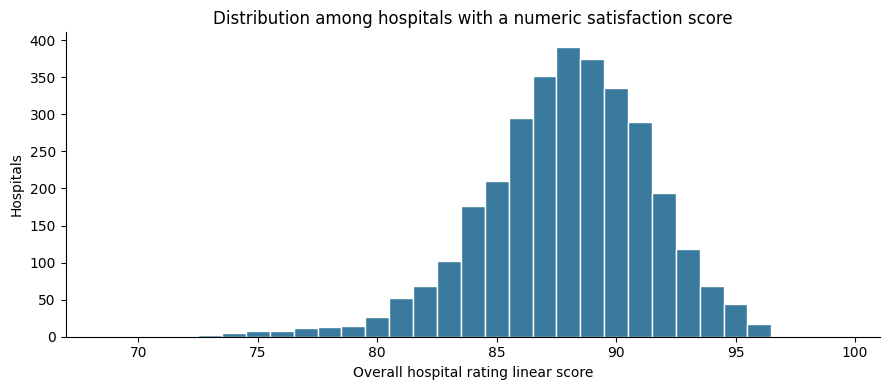

In [5]:
fig, ax = plt.subplots()
ax.hist(target_numeric.dropna().astype(float), bins=np.arange(68.5, 100.5, 1), edgecolor="white", color="#397a9e")
ax.set(xlabel="Overall hospital rating linear score", ylabel="Hospitals",
       title="Distribution among hospitals with a numeric satisfaction score")
plt.tight_layout()
plt.show()


In [6]:
display(Markdown(
    f"**Target findings.** {target_numeric.notna().sum():,} of {len(target_rows):,} hospitals "
    f"({target_numeric.notna().mean():.1%}) have numeric scores; "
    f"{target_numeric.isna().sum():,} ({target_numeric.isna().mean():.1%}) do not. "
    f"Among reported scores, the mean is {target_numeric.mean():.2f}, the median is "
    f"{target_numeric.median():.1f}, and the observed range is "
    f"{target_numeric.min():.0f}–{target_numeric.max():.0f}. "
    "These summaries exclude unavailable scores and should not be interpreted as the satisfaction of hospitals without reported scores."
))


**Target findings.** 3,183 of 4,790 hospitals (66.5%) have numeric scores; 1,607 (33.5%) do not. Among reported scores, the mean is 87.88, the median is 88.0, and the observed range is 69–98. These summaries exclude unavailable scores and should not be interpreted as the satisfaction of hospitals without reported scores.

## 3. Compare hospital coverage and measurement periods

Coverage is checked with identifier sets without merging the source data. The General Information file is the reference hospital list. Different reporting periods limit interpretation of any later predictive relationships: a common download does not imply a common observation window.

In [7]:
general_ids = set(datasets["general"]["Facility ID"])
target_ids = set(target_rows["Facility ID"])
reported_target_ids = set(target_rows.loc[target_numeric.notna(), "Facility ID"])
coverage = pd.DataFrame([
    {"dataset": name, "unique_hospitals": df["Facility ID"].nunique(),
     "in_general_information": len(set(df["Facility ID"]) & general_ids),
     "outside_general_information": len(set(df["Facility ID"]) - general_ids)}
    for name, df in datasets.items()
])
display(coverage)
print("General Information hospitals with no HCAHPS target row:", len(general_ids - target_ids))
period_tables = []
for name, df in datasets.items():
    if {"Start Date", "End Date"}.issubset(df.columns):
        measure_column = "HCAHPS Measure ID" if name == "hcahps" else "Measure ID"
        periods = df[[measure_column, "Start Date", "End Date"]].drop_duplicates().copy()
        periods.insert(0, "dataset", name)
        period_tables.append(periods.rename(columns={measure_column: "measure"}))
period_summary = pd.concat(period_tables, ignore_index=True)
display(period_summary)
display(Markdown("**Period finding.** HCAHPS covers October 2024–September 2025; Medicare spending covers calendar year 2024. Outcomes use several longer periods, some ending in June 2024 and others in 2025. General Information has no start/end date columns, so its reporting period cannot be established from those fields."))


,dataset,unique_hospitals,in_general_information,outside_general_information
0,hcahps,4790,4790,0
1,general,5419,5419,0
2,outcomes,4790,4790,0
3,spending,4626,4626,0


General Information hospitals with no HCAHPS target row: 629


,dataset,measure,Start Date,End Date
0,hcahps,H_COMP_1_A_P,10/01/2024,09/30/2025
1,hcahps,H_COMP_1_SN_P,10/01/2024,09/30/2025
2,hcahps,H_COMP_1_U_P,10/01/2024,09/30/2025
3,hcahps,H_COMP_1_LINEAR_SCORE,10/01/2024,09/30/2025
4,hcahps,H_COMP_1_STAR_RATING,10/01/2024,09/30/2025
...,...,...,...,...
84,outcomes,PSI_13,07/01/2022,06/30/2024
85,outcomes,PSI_14,07/01/2022,06/30/2024
86,outcomes,PSI_15,07/01/2022,06/30/2024
87,outcomes,PSI_90,07/01/2022,06/30/2024


**Period finding.** HCAHPS covers October 2024–September 2025; Medicare spending covers calendar year 2024. Outcomes use several longer periods, some ending in June 2024 and others in 2025. General Information has no start/end date columns, so its reporting period cannot be established from those fields.

## 4. Audit missingness and availability labels

Blanks, **“Not Available”**, and **“Not Applicable”** are counted separately. An empty footnote often means there is no footnote; it does not imply that the associated measure is missing. “Not Applicable” in HCAHPS frequently reflects its long-format layout: a star-rating row and a linear-score row use different value columns. Therefore an all-row missingness percentage is not an estimate of hospital-level predictor availability.

Other nonnumeric values are surfaced below rather than silently treated as valid numbers. Numeric conversion is used only in exploratory copies; no imputation or source-data changes are made. The exact administrative reasons for suppressed or unavailable scores require the release's footnote dictionary, which was not supplied.

In [8]:
missing_reports = {}
for name, df in datasets.items():
    text = df.apply(lambda col: col.str.strip())
    blank = text.isna() | text.eq("")
    not_available = text.apply(lambda col: col.str.casefold().eq("not available"))
    not_applicable = text.apply(lambda col: col.str.casefold().eq("not applicable"))
    report = pd.DataFrame({
        "blank_rows": blank.sum(), "not_available_rows": not_available.sum(),
        "not_applicable_rows": not_applicable.sum(),
        "blank_percent": blank.mean() * 100,
        "not_available_percent": not_available.mean() * 100,
        "not_applicable_percent": not_applicable.mean() * 100,
    })
    missing_reports[name] = report
    print(f"\n{name}: counts are over source rows, including different measure types")
    display(report)



hcahps: counts are over source rows, including different measure types


,blank_rows,not_available_rows,not_applicable_rows,blank_percent,not_available_percent,not_applicable_percent
Facility ID,0,0,0,0.0,0.0,0.0
Facility Name,0,0,0,0.0,0.0,0.0
Address,0,0,0,0.0,0.0,0.0
City/Town,0,0,0,0.0,0.0,0.0
State,0,0,0,0.0,0.0,0.0
ZIP Code,0,0,0,0.0,0.0,0.0
County/Parish,0,0,0,0.0,0.0,0.0
Telephone Number,0,0,0,0.0,0.0,0.0
HCAHPS Measure ID,0,0,0,0.0,0.0,0.0
HCAHPS Question,0,0,0,0.0,0.0,0.0



general: counts are over source rows, including different measure types


,blank_rows,not_available_rows,not_applicable_rows,blank_percent,not_available_percent,not_applicable_percent
Facility ID,0,0,0,0.0,0.0,0.0
Facility Name,0,0,0,0.0,0.0,0.0
Address,0,0,0,0.0,0.0,0.0
City/Town,0,0,0,0.0,0.0,0.0
State,0,0,0,0.0,0.0,0.0
ZIP Code,0,0,0,0.0,0.0,0.0
County/Parish,0,0,0,0.0,0.0,0.0
Telephone Number,0,0,0,0.0,0.0,0.0
Hospital Type,0,0,0,0.0,0.0,0.0
Hospital Ownership,0,0,0,0.0,0.0,0.0



outcomes: counts are over source rows, including different measure types


,blank_rows,not_available_rows,not_applicable_rows,blank_percent,not_available_percent,not_applicable_percent
Facility ID,0,0,0,0.0,0.0,0.0
Facility Name,0,0,0,0.0,0.0,0.0
Address,0,0,0,0.0,0.0,0.0
City/Town,0,0,0,0.0,0.0,0.0
State,0,0,0,0.0,0.0,0.0
ZIP Code,0,0,0,0.0,0.0,0.0
County/Parish,0,0,0,0.0,0.0,0.0
Telephone Number,0,0,0,0.0,0.0,0.0
Measure ID,0,0,0,0.0,0.0,0.0
Measure Name,0,0,0,0.0,0.0,0.0



spending: counts are over source rows, including different measure types


,blank_rows,not_available_rows,not_applicable_rows,blank_percent,not_available_percent,not_applicable_percent
Facility ID,0,0,0,0.0,0.0,0.0
Facility Name,0,0,0,0.0,0.0,0.0
Address,0,0,0,0.0,0.0,0.0
City/Town,0,0,0,0.0,0.0,0.0
State,0,0,0,0.0,0.0,0.0
ZIP Code,0,0,0,0.0,0.0,0.0
County/Parish,0,0,0,0.0,0.0,0.0
Telephone Number,0,0,0,0.0,0.0,0.0
Measure ID,0,0,0,0.0,0.0,0.0
Measure Name,0,0,0,0.0,0.0,0.0


,dataset,measure,hospitals,numeric_count,non_numeric_count,non_numeric_percent
0,hcahps,H_CLEAN_LINEAR_SCORE,4790,3183,1607,33.549061
1,hcahps,H_COMP_1_LINEAR_SCORE,4790,3183,1607,33.549061
2,hcahps,H_COMP_2_LINEAR_SCORE,4790,3183,1607,33.549061
3,hcahps,H_COMP_5_LINEAR_SCORE,4790,3183,1607,33.549061
4,hcahps,H_COMP_6_LINEAR_SCORE,4790,3183,1607,33.549061
5,hcahps,H_HSP_RATING_LINEAR_SCORE,4790,3183,1607,33.549061
6,hcahps,H_QUIET_LINEAR_SCORE,4790,3183,1607,33.549061
7,hcahps,H_RECMND_LINEAR_SCORE,4790,3183,1607,33.549061
8,outcomes,COMP_HIP_KNEE,4790,1706,3084,64.384134
9,outcomes,Hybrid_HWM,4790,4261,529,11.043841


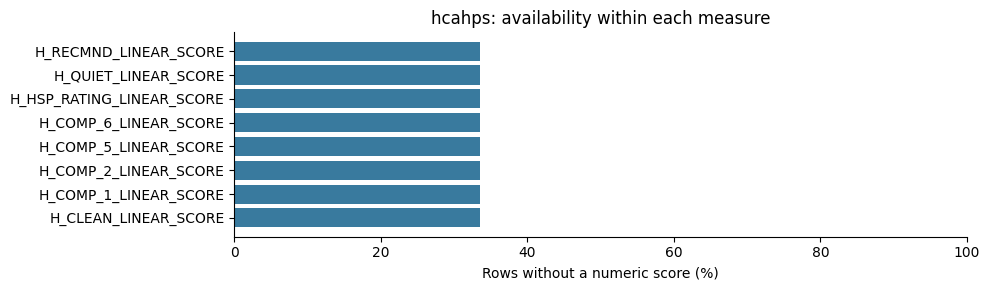

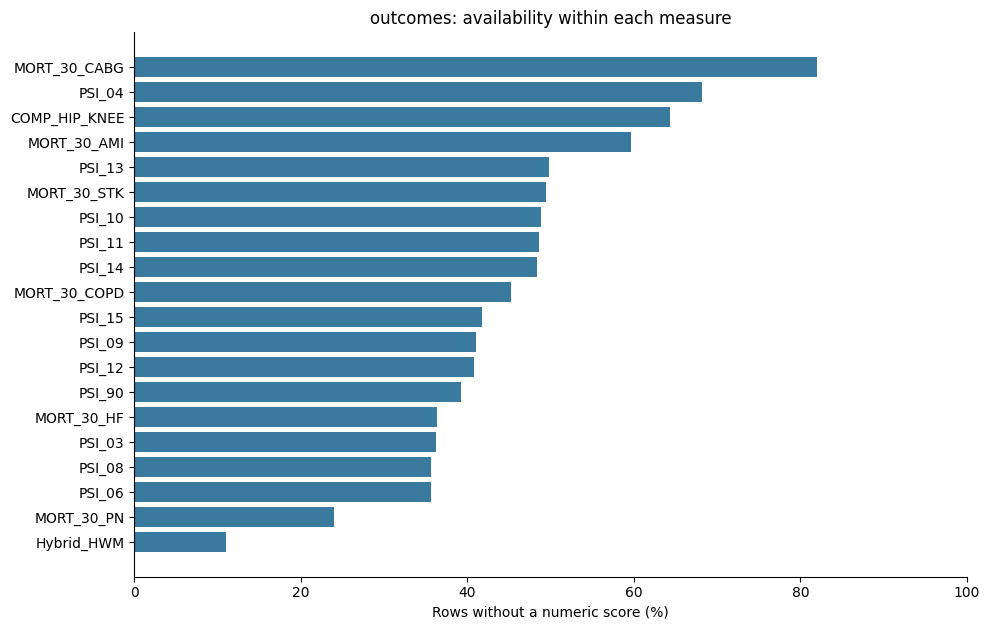

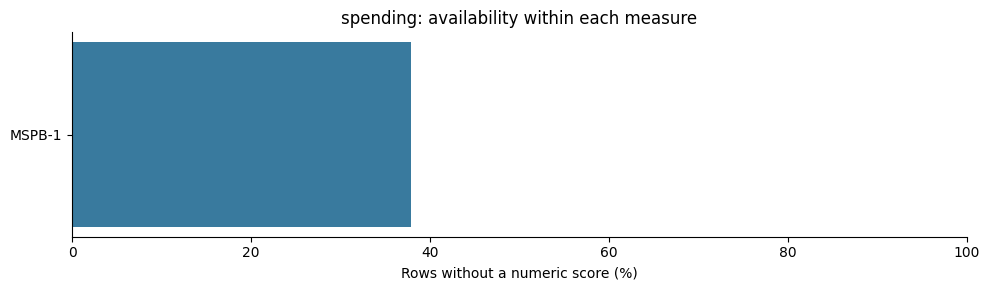

In [9]:
measure_reports = []
for name, measure_col, value_col in [
    ("hcahps", "HCAHPS Measure ID", "HCAHPS Linear Mean Value"),
    ("outcomes", "Measure ID", "Score"),
    ("spending", "Measure ID", "Score"),
]:
    df = datasets[name]
    if name == "hcahps":
        df = df.loc[df[measure_col].str.endswith("_LINEAR_SCORE")]
    for measure, group in df.groupby(measure_col, sort=True):
        raw = group[value_col].str.strip()
        numeric = pd.to_numeric(raw, errors="coerce")
        measure_reports.append({"dataset": name, "measure": measure,
                                "hospitals": group["Facility ID"].nunique(),
                                "numeric_count": int(numeric.notna().sum()),
                                "non_numeric_count": int(numeric.isna().sum()),
                                "non_numeric_percent": float(numeric.isna().mean() * 100)})
        labels = raw[numeric.isna()].value_counts()
        unexpected = labels.loc[~labels.index.str.casefold().isin(["", "not available", "not applicable"])]
        if not unexpected.empty:
            print(name, measure, "additional nonnumeric labels:", unexpected.to_dict())
measure_availability = pd.DataFrame(measure_reports)
display(measure_availability)
for name in ["hcahps", "outcomes", "spending"]:
    plot_data = measure_availability.loc[measure_availability["dataset"].eq(name)].sort_values("non_numeric_percent")
    fig, ax = plt.subplots(figsize=(10, max(3, .32 * len(plot_data))))
    ax.barh(plot_data["measure"], plot_data["non_numeric_percent"], color="#397a9e")
    ax.set(xlim=(0, 100), xlabel="Rows without a numeric score (%)", title=f"{name}: availability within each measure")
    plt.tight_layout()
    plt.show()


## 5. Describe hospital characteristics and target availability

These descriptive tables compare reported and unreported targets by hospital type. They retain General Information hospitals without an HCAHPS target row as a separate group. This is an availability audit, not a prediction model or a test of causation.

In [10]:
general = datasets["general"]
for column in ["Hospital Type", "Hospital Ownership", "Emergency Services"]:
    display(general[column].value_counts(dropna=False).to_frame("hospitals"))
status = np.where(general["Facility ID"].isin(reported_target_ids), "Numeric target",
                  np.where(general["Facility ID"].isin(target_ids), "Target unavailable", "No target row"))
status_by_type = pd.crosstab(general["Hospital Type"], status)
display(status_by_type)
display(Markdown("**Coverage interpretation.** Target reporting differs across hospital types, so a later analysis limited to numeric targets will represent a selected subset of hospitals. The reporting pattern alone does not establish why a score is unavailable."))


,hospitals
Hospital Type,
Acute Care Hospitals,3107
Critical Access Hospitals,1382
Psychiatric,624
Acute Care - Veterans Administration,132
Childrens,94
Rural Emergency Hospital,43
Acute Care - Department of Defense,32
Long-term,5


,hospitals
Hospital Ownership,
Voluntary non-profit - Private,2322
Proprietary,1063
Government - Hospital District or Authority,512
Government - Local,393
Voluntary non-profit - Other,353
Voluntary non-profit - Church,264
Government - State,209
Veterans Health Administration,132
Physician,80


,hospitals
Emergency Services,
Yes,4495
No,924


col_0,No target row,Numeric target,Target unavailable
Hospital Type,,,
Acute Care - Department of Defense,0,27,5
Acute Care - Veterans Administration,0,110,22
Acute Care Hospitals,0,2699,408
Childrens,0,0,94
Critical Access Hospitals,0,347,1035
Long-term,5,0,0
Psychiatric,624,0,0
Rural Emergency Hospital,0,0,43


**Coverage interpretation.** Target reporting differs across hospital types, so a later analysis limited to numeric targets will represent a selected subset of hospitals. The reporting pattern alone does not establish why a score is unavailable.

In [11]:
outcome_availability = measure_availability.loc[measure_availability["dataset"].eq("outcomes")]
spending_availability = measure_availability.loc[measure_availability["dataset"].eq("spending")].iloc[0]
missing_general = len(general_ids - target_ids)
display(Markdown(
    "## Findings and implications\n\n"
    f"- The reference file contains **{len(general_ids):,} hospitals**; **{missing_general:,}** have no target-measure row.\n"
    f"- **{target_numeric.notna().sum():,} hospitals** have a numeric overall rating linear score; "
    f"**{target_numeric.isna().sum():,}** target rows are nonnumeric. No target values were filled in.\n"
    f"- Across the {len(outcome_availability)} outcome measures, the share of nonnumeric score rows ranges from "
    f"**{outcome_availability['non_numeric_percent'].min():.1f}% to {outcome_availability['non_numeric_percent'].max():.1f}%**. "
    "Missingness must be assessed measure by measure.\n"
    f"- Medicare spending has **{int(spending_availability['numeric_count']):,} numeric scores** out of "
    f"**{int(spending_availability['hospitals']):,} reporting hospital rows**. Its missingness and hospital coverage are separate issues.\n"
    "- Footnote blanks and structurally inapplicable HCAHPS fields should not be treated as ordinary missing predictors. "
    "The administrative reasons for unavailable values remain unresolved without the release dictionary.\n"
    "- The files have different measurement windows. This supports a cross-sectional exploration, not a claim about future prediction.\n\n"
    "**Answer at this stage:** The target and candidate data sources are identified, but initial exploration cannot determine "
    "how accurately they predict satisfaction. That requires a later, separately evaluated modeling analysis. "
    "No modeling dataset has been merged, no values have been imputed, and no prediction models have been fitted."
))


## Findings and implications

- The reference file contains **5,419 hospitals**; **629** have no target-measure row.
- **3,183 hospitals** have a numeric overall rating linear score; **1,607** target rows are nonnumeric. No target values were filled in.
- Across the 20 outcome measures, the share of nonnumeric score rows ranges from **11.0% to 82.0%**. Missingness must be assessed measure by measure.
- Medicare spending has **2,872 numeric scores** out of **4,626 reporting hospital rows**. Its missingness and hospital coverage are separate issues.
- Footnote blanks and structurally inapplicable HCAHPS fields should not be treated as ordinary missing predictors. The administrative reasons for unavailable values remain unresolved without the release dictionary.
- The files have different measurement windows. This supports a cross-sectional exploration, not a claim about future prediction.

**Answer at this stage:** The target and candidate data sources are identified, but initial exploration cannot determine how accurately they predict satisfaction. That requires a later, separately evaluated modeling analysis. No modeling dataset has been merged, no values have been imputed, and no prediction models have been fitted.

## Sources and limits

The supplied local CSVs are the source for all counts, dates, and descriptive statistics above. Their SHA-256 hashes are recorded near the start. Download and release dates were not supplied, so they are not inferred.

- [CMS hospital data catalog](https://data.cms.gov/provider-data/topics/hospitals)
- [CMS HCAHPS hospital dataset](https://data.cms.gov/provider-data/dataset/dgck-syfz)
- [CMS HCAHPS overview](https://www.cms.gov/data-research/research/consumer-assessment-healthcare-providers-systems/hospital-cahps-hcahps)

The intended 0–100 target scale comes from the project specification; the observed values and labels are verified in the CSV. The accompanying release dictionary was not included in the supplied files. Any later feature selection should consider information leakage: the CMS overall hospital star rating includes patient experience, and other HCAHPS measures share the same survey as the target. This notebook does not use those fields to predict the target.